In [33]:
from pathlib import Path

# Locate the figures folder
FIGURE_DIR = Path("results/figures")

if not FIGURE_DIR.exists():
    FIGURE_DIR = Path("../results/figures")

# Create the folder if it doesn't exist
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Figures will be saved to:", FIGURE_DIR.resolve())

Figures will be saved to: /Users/darran/Desktop/AI/AI Project/international-football-ml/results/figures


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
import pandas as pd

# Load the international football results dataset
df = pd.read_csv("../data/results.csv")

# Display the first 5 rows
df.head()

,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
0,1872-11-30,Scotland,England,0,0,Friendly,Glasgow,Scotland,False
1,1873-03-08,England,Scotland,4,2,Friendly,London,England,False
2,1874-03-07,Scotland,England,2,1,Friendly,Glasgow,Scotland,False
3,1875-03-06,England,Scotland,2,2,Friendly,London,England,False
4,1876-03-04,Scotland,England,3,0,Friendly,Glasgow,Scotland,False


In [4]:
df.shape

(49945, 9)

In [5]:
df.columns

Index(['date', 'home_team', 'away_team', 'home_score', 'away_score',
       'tournament', 'city', 'country', 'neutral'],
      dtype='str')

In [6]:
df.describe()

,home_score,away_score
count,49945.000000,49945.000000
mean,1.756072,1.182701
std,1.772078,1.401670
min,0.000000,0.000000
25%,1.000000,0.000000
50%,1.000000,1.000000
75%,2.000000,2.000000
max,31.000000,21.000000


In [7]:
df.isnull().sum()

date          0
home_team     0
away_team     0
home_score    0
away_score    0
tournament    0
city          0
country       0
neutral       0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 49945 entries, 0 to 49944
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   date        49945 non-null  str  
 1   home_team   49945 non-null  str  
 2   away_team   49945 non-null  str  
 3   home_score  49945 non-null  int64
 4   away_score  49945 non-null  int64
 5   tournament  49945 non-null  str  
 6   city        49945 non-null  str  
 7   country     49945 non-null  str  
 8   neutral     49945 non-null  bool 
dtypes: bool(1), int64(2), str(6)
memory usage: 3.1 MB


In [10]:
df["date"].min(), df["date"].max()

('1872-11-30', '2026-10-06')

In [11]:
# Convert the date column from text into datetime format
df["date"] = pd.to_datetime(df["date"])

# Check the data type
df["date"].info()

<class 'pandas.Series'>
RangeIndex: 49945 entries, 0 to 49944
Series name: date
Non-Null Count  Dtype         
--------------  -----         
49945 non-null  datetime64[us]
dtypes: datetime64[us](1)
memory usage: 390.3 KB


In [12]:
# Create a new column called 'result'
df["result"] = np.where(
    df["home_score"] > df["away_score"], "Home Win",
    np.where(
        df["home_score"] == df["away_score"], "Draw",
        "Away Win"
    )
)

# Count each outcome
df["result"].value_counts()

result
Home Win    24473
Away Win    14131
Draw        11341
Name: count, dtype: int64

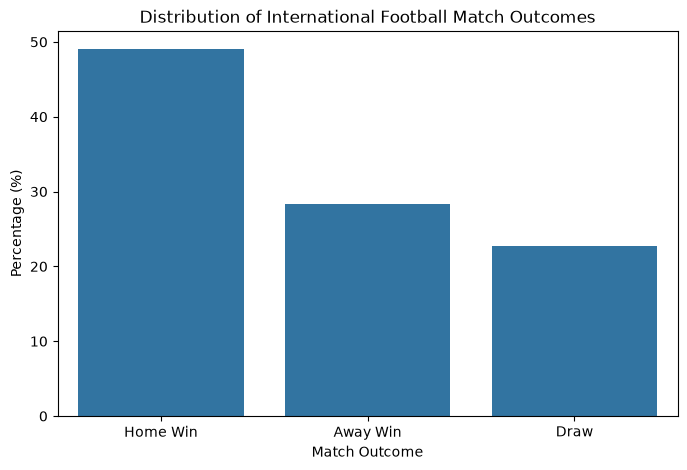

In [32]:
# Calculate the percentage of each outcome
outcome_percentages = df["result"].value_counts(normalize=True) * 100

# Plot the results
plt.figure(figsize=(8, 5))
sns.barplot(
    x=outcome_percentages.index,
    y=outcome_percentages.values
)

plt.title("Distribution of International Football Match Outcomes")
plt.xlabel("Match Outcome")
plt.ylabel("Percentage (%)")
plt.savefig("../results/figures/outcome_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [14]:
# Calculate outcome percentages for neutral and non-neutral matches
venue_results = pd.crosstab(
    df["neutral"],
    df["result"],
    normalize="index"
) * 100

# Display the results
venue_results

result,Away Win,Draw,Home Win
neutral,,,
False,26.444681,22.823093,50.732226
True,33.398614,22.386261,44.215125


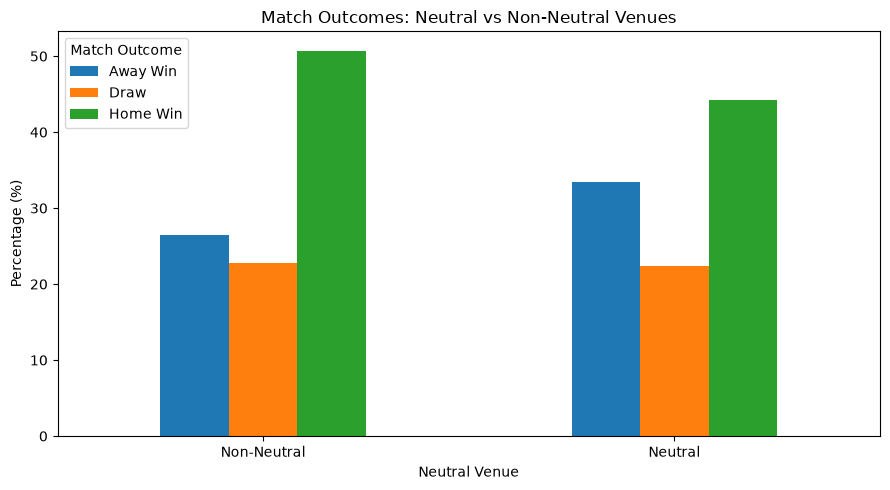

In [15]:
venue_results.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Match Outcomes: Neutral vs Non-Neutral Venues")
plt.xlabel("Neutral Venue")
plt.ylabel("Percentage (%)")
plt.xticks(
    ticks=[0, 1],
    labels=["Non-Neutral", "Neutral"],
    rotation=0
)

plt.legend(title="Match Outcome")
plt.tight_layout()
plt.show()

In [16]:
# Extract the year from each match date
df["year"] = df["date"].dt.year

# Group matches by decade and venue type
df["decade"] = (df["year"] // 10) * 10

# Calculate home win percentage by decade and venue type
home_win_by_decade = df.pivot_table(
    index="decade",
    columns="neutral",
    values="result",
    aggfunc=lambda x: (x == "Home Win").mean() * 100
)

# Display results
home_win_by_decade.tail(15)

neutral,False,True
decade,,
1880,49.090909,NaN
1890,50.000000,100.000000
1900,44.360902,60.000000
1910,51.186441,82.857143
1920,49.656121,76.923077
1930,52.289670,53.571429
1940,54.407295,49.142857
1950,49.350649,47.701149
1960,52.240143,52.638701


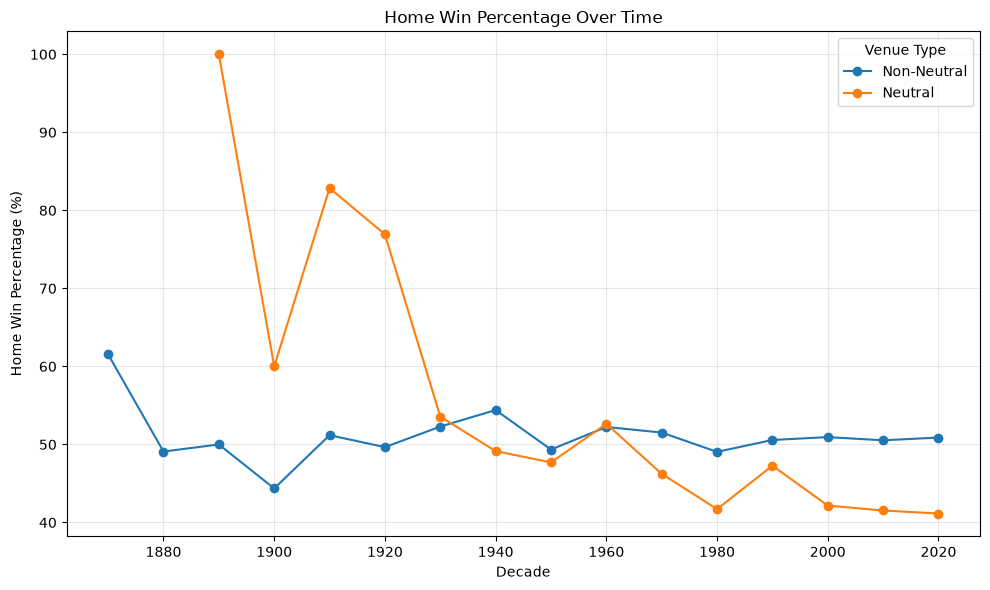

In [34]:
home_win_by_decade.plot(
    figsize=(10, 6),
    marker="o"
)

plt.title("Home Win Percentage Over Time")
plt.xlabel("Decade")
plt.ylabel("Home Win Percentage (%)")
plt.legend(
    labels=["Non-Neutral", "Neutral"],
    title="Venue Type"
)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "home_advantage.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [18]:
# Count matches by decade and venue type
match_counts = pd.crosstab(
    df["decade"],
    df["neutral"]
)

# Display the most recent 15 decades
match_counts.tail(15)

neutral,False,True
decade,,
1880,55,0
1890,58,1
1900,133,5
1910,295,35
1920,727,104
1930,939,140
1940,658,175
1950,1309,348
1960,2232,739


In [19]:
# Calculate home win percentages and match counts together
decade_analysis = pd.DataFrame({
    "Non-Neutral Matches": match_counts[False],
    "Neutral Matches": match_counts[True],
    "Non-Neutral Home Win %": home_win_by_decade[False],
    "Neutral Home Win %": home_win_by_decade[True]
})

decade_analysis.tail(15)

,Non-Neutral Matches,Neutral Matches,Non-Neutral Home Win %,Neutral Home Win %
decade,,,,
1880,55,0,49.090909,NaN
1890,58,1,50.000000,100.000000
1900,133,5,44.360902,60.000000
1910,295,35,51.186441,82.857143
1920,727,104,49.656121,76.923077
1930,939,140,52.289670,53.571429
1940,658,175,54.407295,49.142857
1950,1309,348,49.350649,47.701149
1960,2232,739,52.240143,52.638701


In [20]:
df[df["year"] >= 1990].shape

(32821, 12)

In [21]:
# Create a separate dataset containing matches from 1990 onwards
df_model = df[df["year"] >= 1990].copy()

# Sort matches chronologically
df_model = df_model.sort_values("date").reset_index(drop=True)

# Check the new dataset
print("Number of matches:", len(df_model))
print("First match:", df_model["date"].min())
print("Last match:", df_model["date"].max())

Number of matches: 32821
First match: 1990-01-12 00:00:00
Last match: 2026-10-06 00:00:00


In [22]:
# Calculate outcome counts
df_model["result"].value_counts()

result
Home Win    15907
Away Win     9217
Draw         7697
Name: count, dtype: int64

In [23]:
# Calculate outcome percentages
df_model["result"].value_counts(normalize=True) * 100

result
Home Win    48.465921
Away Win    28.082630
Draw        23.451449
Name: proportion, dtype: float64

In [24]:
# Count how many matches each team has participated in
team_appearances = pd.concat([
    df_model["home_team"],
    df_model["away_team"]
]).value_counts()

# Display the 10 most frequent teams
team_appearances.head(10)

Mexico           665
United States    627
Saudi Arabia     585
South Korea      561
Brazil           538
Japan            530
Costa Rica       519
Egypt            518
Jamaica          517
Zambia           511
Name: count, dtype: int64

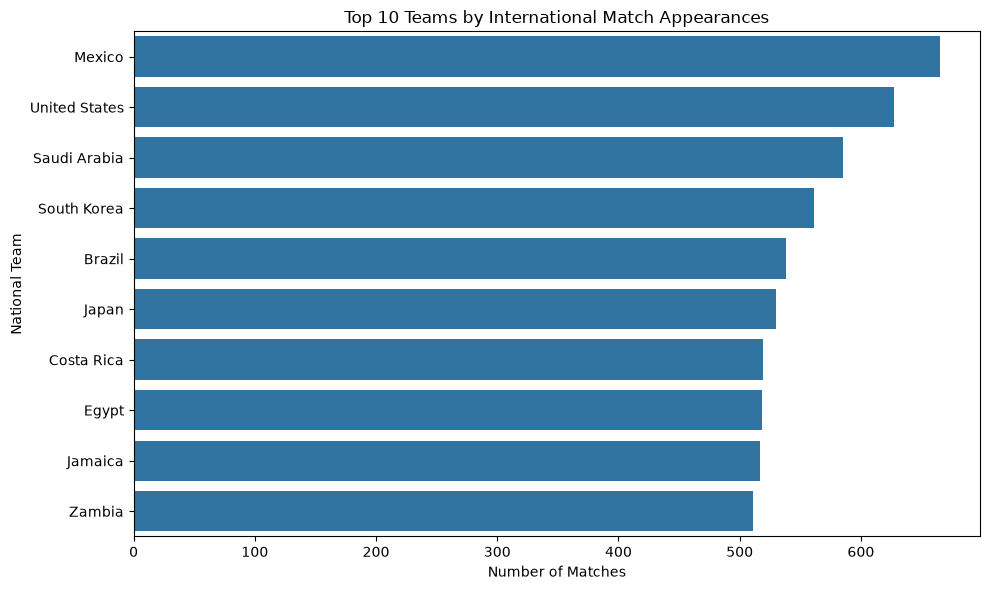

In [35]:
# Plot the 10 teams with the most appearances
plt.figure(figsize=(10, 6))

sns.barplot(
    x=team_appearances.head(10).values,
    y=team_appearances.head(10).index
)

plt.title("Top 10 Teams by International Match Appearances")
plt.xlabel("Number of Matches")
plt.ylabel("National Team")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "top_teams.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [26]:
# Count matches by tournament
tournament_counts = df_model["tournament"].value_counts()

# Display the 15 most common tournaments
tournament_counts.head(15)

tournament
Friendly                                10758
FIFA World Cup qualification             6977
UEFA Euro qualification                  2114
African Cup of Nations qualification     1925
UEFA Nations League                       762
FIFA World Cup                            656
African Cup of Nations                    642
AFC Asian Cup qualification               632
CFU Caribbean Cup qualification           508
CONCACAF Nations League                   495
CECAFA Cup                                422
Gold Cup                                  420
Island Games                              384
Copa América                              378
COSAFA Cup                                354
Name: count, dtype: int64

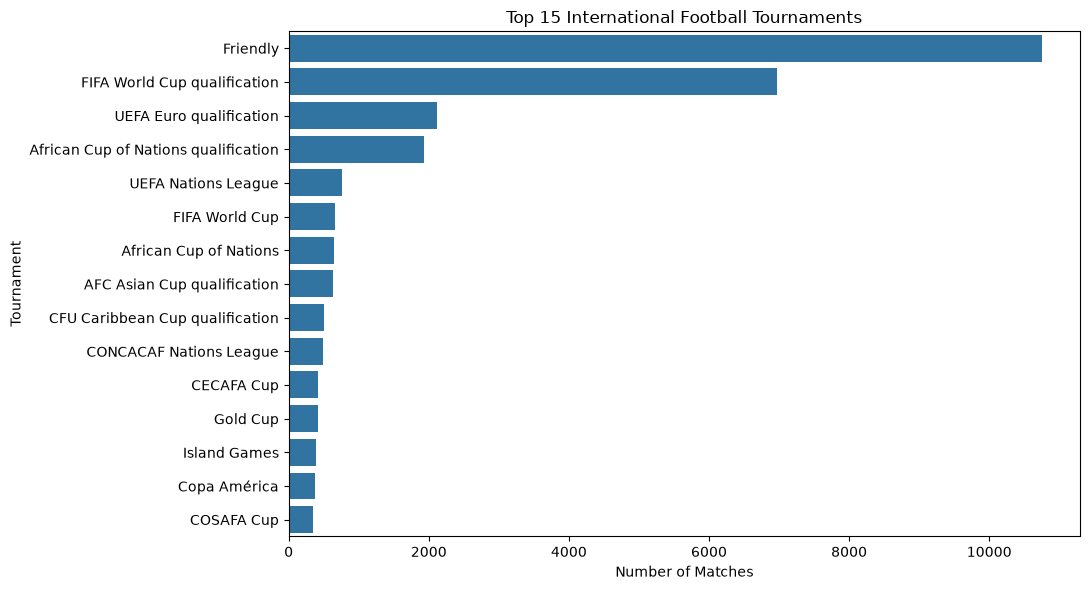

In [36]:
plt.figure(figsize=(11, 6))

sns.barplot(
    x=tournament_counts.head(15).values,
    y=tournament_counts.head(15).index
)

plt.title("Top 15 International Football Tournaments")
plt.xlabel("Number of Matches")
plt.ylabel("Tournament")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "tournament_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [28]:
# Classify matches as friendly or competitive
df_model["match_type"] = np.where(
    df_model["tournament"] == "Friendly",
    "Friendly",
    "Competitive"
)

# Count each match type
match_type_counts = df_model["match_type"].value_counts()

# Calculate percentages
match_type_percentages = (
    match_type_counts / len(df_model) * 100
)

match_type_percentages

match_type
Competitive    67.222205
Friendly       32.777795
Name: count, dtype: float64

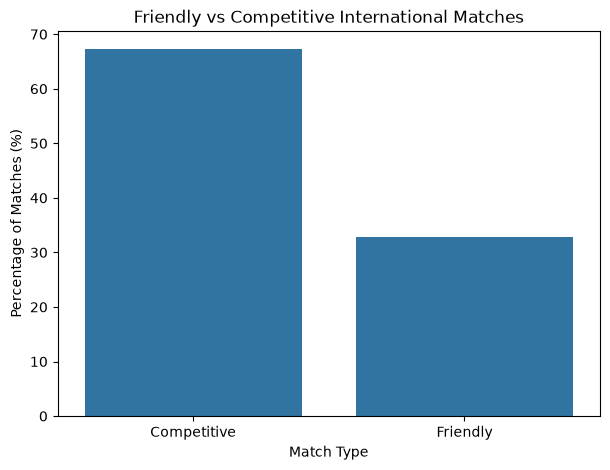

In [37]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=match_type_percentages.index,
    y=match_type_percentages.values
)

plt.title("Friendly vs Competitive International Matches")
plt.xlabel("Match Type")
plt.ylabel("Percentage of Matches (%)")

plt.savefig(FIGURE_DIR / "match_type_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [30]:
# Calculate average goals scored by home and away teams
average_home_goals = df_model["home_score"].mean()
average_away_goals = df_model["away_score"].mean()

# Calculate average total goals per match
average_total_goals = (
    df_model["home_score"] + df_model["away_score"]
).mean()

print("Average home goals:", average_home_goals)
print("Average away goals:", average_away_goals)
print("Average total goals:", average_total_goals)

Average home goals: 1.6525395326163128
Average away goals: 1.1100514914231743
Average total goals: 2.762591024039487


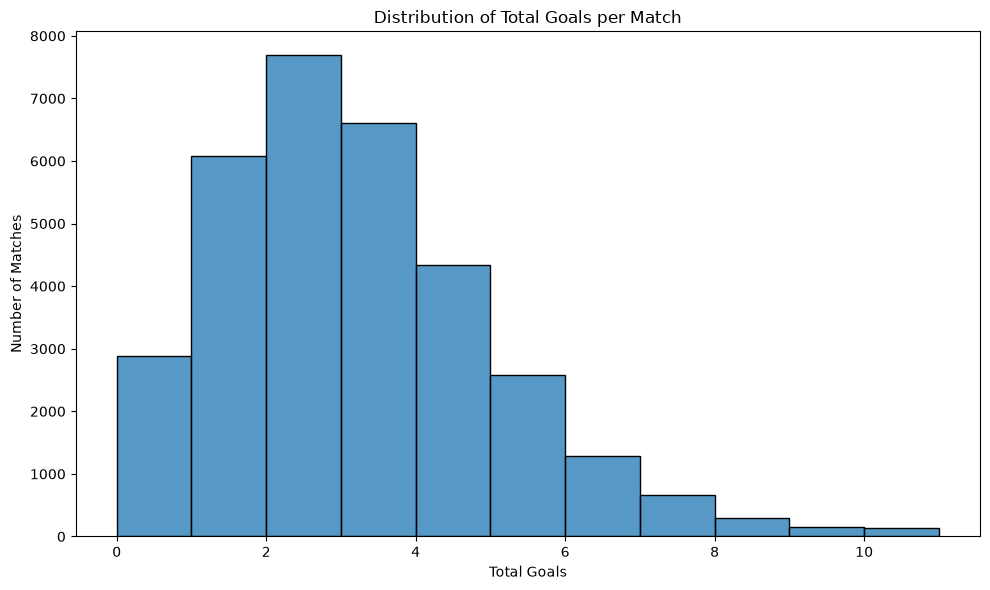

In [38]:
# Create a column for total goals
df_model["total_goals"] = (
    df_model["home_score"] + df_model["away_score"]
)

# Plot the distribution of total goals
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_model,
    x="total_goals",
    bins=range(0, 12),
    kde=False
)

plt.title("Distribution of Total Goals per Match")
plt.xlabel("Total Goals")
plt.ylabel("Number of Matches")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "goal_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()

## EDA Summary

The exploratory data analysis examined 32,821 international football matches played between 1990 and October 2026.

The analysis revealed that home wins were the most frequent outcome, accounting for approximately 48.47% of matches. Away wins represented 28.08%, while draws accounted for 23.45%. This suggests that home advantage may play an important role in international football.

Further analysis showed that home teams scored an average of 1.65 goals per match, compared to 1.11 goals for away teams. The average total goals per match was approximately 2.76.

In terms of match types, competitive fixtures accounted for 67.22% of the dataset, while friendlies represented 32.78%.

The analysis also highlighted differences in international match participation across national teams and the variety of tournaments represented in the dataset.

These findings provide useful context for the next stages of the project. In particular, home advantage, tournament type and historical team performance will be investigated as potential predictors of match outcomes.